<a href="https://colab.research.google.com/github/suma-2114/PowerBIAssignment1/blob/main/Capstone_Project%2C_(Covid_19).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import plotly.express as px
from prophet import Prophet

In [3]:
df = pd.read_csv("/content/covid_19_clean_complete.csv")

df.head()

,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa


In [4]:
df['Date'] = pd.to_datetime(df['Date'])

In [5]:
global_data = df.groupby('Date')[['Confirmed','Deaths','Recovered','Active']].sum().reset_index()

global_data.head()

,Date,Confirmed,Deaths,Recovered,Active
0,2020-01-22,555,17,28,510
1,2020-01-23,654,18,30,606
2,2020-01-24,941,26,36,879
3,2020-01-25,1434,42,39,1353
4,2020-01-26,2118,56,52,2010


In [6]:
fig = px.line(global_data,
              x='Date',
              y='Confirmed',
              title='Global COVID-19 Confirmed Cases Trend')

fig.show()

In [7]:
fig = px.line(global_data,
              x='Date',
              y=['Deaths','Recovered'],
              title='Deaths vs Recovered Cases')

fig.show()

In [8]:
fig = px.line(global_data,
              x='Date',
              y='Active',
              title='Active COVID Cases Over Time')

fig.show()

In [9]:
prophet_data = global_data[['Date','Confirmed']]

prophet_data = prophet_data.rename(columns={
    'Date':'ds',
    'Confirmed':'y'
})

prophet_data.head()

,ds,y
0,2020-01-22,555
1,2020-01-23,654
2,2020-01-24,941
3,2020-01-25,1434
4,2020-01-26,2118


In [10]:
model = Prophet()

model.fit(prophet_data)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [11]:
future = model.make_future_dataframe(periods=7)

forecast = model.predict(future)

forecast[['ds','yhat','yhat_lower','yhat_upper']].tail()

,ds,yhat,yhat_lower,yhat_upper
190,2020-07-30,1.674383e+07,1.663630e+07,1.684956e+07
191,2020-07-31,1.695907e+07,1.685655e+07,1.706684e+07
192,2020-08-01,1.716669e+07,1.705751e+07,1.728439e+07
193,2020-08-02,1.736419e+07,1.725690e+07,1.747574e+07
194,2020-08-03,1.755880e+07,1.744837e+07,1.767705e+07


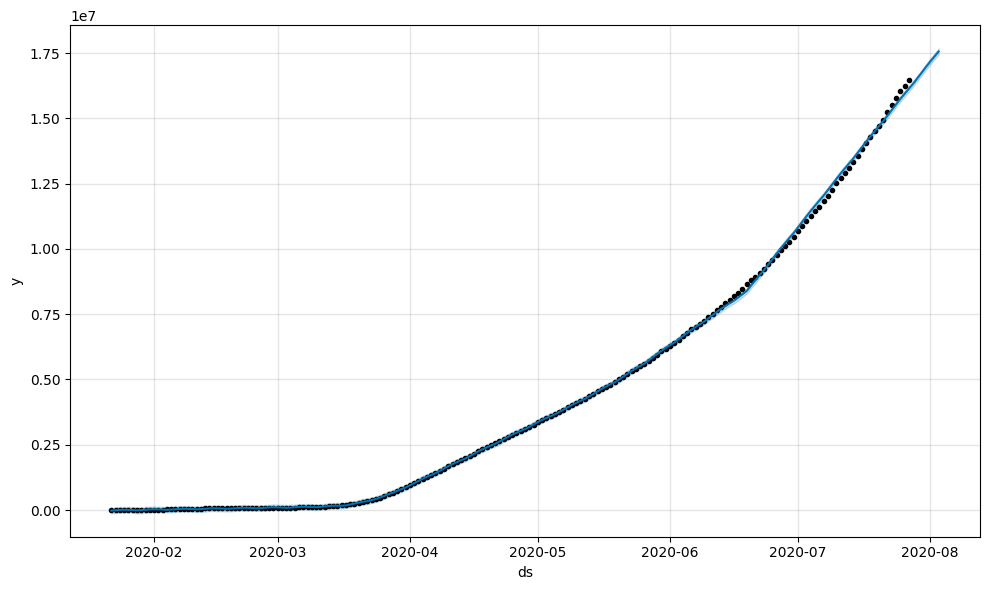

In [12]:
fig = model.plot(forecast)

In [13]:
forecast_plot = px.line(forecast,
                        x='ds',
                        y='yhat',
                        title='COVID-19 Cases Prediction (Next Week)')

forecast_plot.show()